In [5]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path("/kaggle/input/datasets/romisaa8abualyazed/skin-data/tensorflow_original/metadata.csv")

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (24930, 14)

Columns:
['image_path', 'diagnosis', 'source', 'sha256', 'lesion_id', 'group_id', 'age', 'sex', 'anatom_site_general_challenge', 'split', 'age_missing', 'site_missing', 'sex_missing', 'label']

Data types:
image_path                        object
diagnosis                         object
source                            object
sha256                            object
lesion_id                         object
group_id                          object
age                              float64
sex                               object
anatom_site_general_challenge     object
split                             object
age_missing                        int64
site_missing                       int64
sex_missing                        int64
label                              int64
dtype: object

First 5 rows:


,image_path,diagnosis,source,sha256,lesion_id,group_id,age,sex,anatom_site_general_challenge,split,age_missing,site_missing,sex_missing,label
0,/content/isic/train/ISIC_0000002.jpg,mel,ISIC2019,fc30b8a43cc0ae238fcaba71155d831dfb86e9eb2ccc57...,NaN,ISIC_IMAGE_ISIC_0000002.jpg,60.0,female,upper extremity,train,0,0,0,5
1,/content/isic/train/ISIC_0000004.jpg,mel,ISIC2019,1fe6ec92526cf04b67cd5493606922a60faf7104a1a144...,NaN,ISIC_IMAGE_ISIC_0000004.jpg,80.0,male,posterior torso,val,0,0,0,5
2,/content/isic/train/ISIC_0000013.jpg,mel,ISIC2019,b6a83b742377478ca79a2bb4923114ae78352fbb38b61c...,NaN,ISIC_IMAGE_ISIC_0000013.jpg,30.0,female,posterior torso,train,0,0,0,5
3,/content/isic/train/ISIC_0000022_downsampled.jpg,mel,ISIC2019,61f7243c878a24ac4a717f3f29931dc0c2d6a8cff11844...,NaN,ISIC_IMAGE_ISIC_0000022_downsampled.jpg,55.0,female,lower extremity,test,0,0,0,5
4,/content/isic/train/ISIC_0000026_downsampled.jpg,mel,ISIC2019,05806758b5db7bc44cba270d868c55dc2957581f5a2f0c...,NaN,ISIC_IMAGE_ISIC_0000026_downsampled.jpg,30.0,female,lower extremity,train,0,0,0,5



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24930 entries, 0 to 24929
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   image_path                     24930 non-null  object 
 1   diagnosis                      24930 non-null  object 
 2   source                         24930 non-null  object 
 3   sha256                         24930 non-null  object 
 4   lesion_id                      10013 non-null  object 
 5   group_id                       24930 non-null  object 
 6   age                            24930 non-null  float64
 7   sex                            24930 non-null  object 
 8   anatom_site_general_challenge  24930 non-null  object 
 9   split                          24930 non-null  object 
 10  age_missing                    24930 non-null  int64  
 11  site_missing                   24930 non-null  int64  
 12  sex_missing             

# ak + akiec

In [6]:

# Create a separate diagnosis column for EDA
df["diagnosis_merged"] = (
    df["diagnosis"]
    .str.strip()
    .str.lower()
    .replace({
        "ak": "ak_akiec",
        "akiec": "ak_akiec"
    })
)

# 1. Verify the merged class counts
print("Merged diagnosis distribution:")

display(
    df["diagnosis_merged"]
    .value_counts()
    .rename_axis("diagnosis")
    .to_frame("image_count")
)

# 2. Check the merged class by source
print("\nMerged diagnosis by source:")

display(
    pd.crosstab(
        df["source"],
        df["diagnosis_merged"],
        margins=True
    )
)

# 3. Verify that original labels remain unchanged
print("\nOriginal diagnosis and label mapping:")

display(
    df[df["diagnosis"].isin(["ak", "akiec"])]
    .groupby(["source", "diagnosis", "label"])
    .size()
    .reset_index(name="image_count")
)


Merged diagnosis distribution:


,image_count
diagnosis,
nv,9203
mel,5625
bcc,3830
bkl,3709
ak_akiec,1186
scc,628
vasc,395
df,354



Merged diagnosis by source:


diagnosis_merged,ak_akiec,bcc,bkl,df,mel,nv,scc,vasc,All
source,,,,,,,,,
HAM10000,327,514,1099,115,1113,6703,0,142,10013
ISIC2019,859,3316,2610,239,4512,2500,628,253,14917
All,1186,3830,3709,354,5625,9203,628,395,24930



Original diagnosis and label mapping:


,source,diagnosis,label,image_count
0,HAM10000,akiec,1,327
1,ISIC2019,ak,0,859


 # Data Source Analysis & Diagnosis Distribution

In [7]:

import pandas as pd

# Create a merged diagnosis column for EDA only
df["diagnosis_merged"] = (
    df["diagnosis"]
    .str.strip()
    .str.lower()
    .replace({
        "ak": "ak_akiec",
        "akiec": "ak_akiec"
    })
)

# 1. Number of images from each source
print("1. IMAGE COUNT BY SOURCE")

source_counts = df["source"].value_counts(dropna=False)

source_summary = pd.DataFrame({
    "image_count": source_counts,
    "percentage": (
        source_counts / len(df) * 100
    ).round(2)
})

display(source_summary)


# 2. Merged diagnosis distribution within each source
print("\n2. MERGED DIAGNOSIS DISTRIBUTION BY SOURCE")

source_diagnosis_counts = pd.crosstab(
    df["source"],
    df["diagnosis_merged"],
    margins=True
)

display(source_diagnosis_counts)


# 3. Percentage of each merged diagnosis within its source
print("\n3. MERGED DIAGNOSIS PERCENTAGE WITHIN EACH SOURCE")

source_diagnosis_percent = pd.crosstab(
    df["source"],
    df["diagnosis_merged"],
    normalize="index"
).mul(100).round(2)

display(source_diagnosis_percent)


# 4. Check the original diagnosis-label mapping
print("\n4. ORIGINAL LABEL MAPPING ACROSS SOURCES")

display(
    df.groupby(["source", "diagnosis", "label"], dropna=False)
      .size()
      .reset_index(name="image_count")
      .sort_values(["source", "diagnosis", "label"])
)


# 5. Verify the merged AK/AKIEC class
print("\n5. MERGED AK/AKIEC CLASS")

merged_class = df[
    df["diagnosis_merged"] == "ak_akiec"
]

print("Total AK/AKIEC images:", len(merged_class))

display(
    merged_class.groupby(["source", "diagnosis"])
    .size()
    .reset_index(name="image_count")
)


1. IMAGE COUNT BY SOURCE


,image_count,percentage
source,,
ISIC2019,14917,59.84
HAM10000,10013,40.16



2. MERGED DIAGNOSIS DISTRIBUTION BY SOURCE


diagnosis_merged,ak_akiec,bcc,bkl,df,mel,nv,scc,vasc,All
source,,,,,,,,,
HAM10000,327,514,1099,115,1113,6703,0,142,10013
ISIC2019,859,3316,2610,239,4512,2500,628,253,14917
All,1186,3830,3709,354,5625,9203,628,395,24930



3. MERGED DIAGNOSIS PERCENTAGE WITHIN EACH SOURCE


diagnosis_merged,ak_akiec,bcc,bkl,df,mel,nv,scc,vasc
source,,,,,,,,
HAM10000,3.27,5.13,10.98,1.15,11.12,66.94,0.00,1.42
ISIC2019,5.76,22.23,17.50,1.60,30.25,16.76,4.21,1.70



4. ORIGINAL LABEL MAPPING ACROSS SOURCES


,source,diagnosis,label,image_count
0,HAM10000,akiec,1,327
1,HAM10000,bcc,2,514
2,HAM10000,bkl,3,1099
3,HAM10000,df,4,115
4,HAM10000,mel,5,1113
5,HAM10000,nv,6,6703
6,HAM10000,vasc,8,142
7,ISIC2019,ak,0,859
8,ISIC2019,bcc,2,3316
9,ISIC2019,bkl,3,2610



5. MERGED AK/AKIEC CLASS
Total AK/AKIEC images: 1186


,source,diagnosis,image_count
0,HAM10000,akiec,327
1,ISIC2019,ak,859


1. IMAGE COUNT PER MERGED DIAGNOSIS CLASS


,image_count,percentage
diagnosis_merged,,
nv,9203,36.92
mel,5625,22.56
bcc,3830,15.36
bkl,3709,14.88
ak_akiec,1186,4.76
scc,628,2.52
vasc,395,1.58
df,354,1.42



2. MERGED CLASS DISTRIBUTION


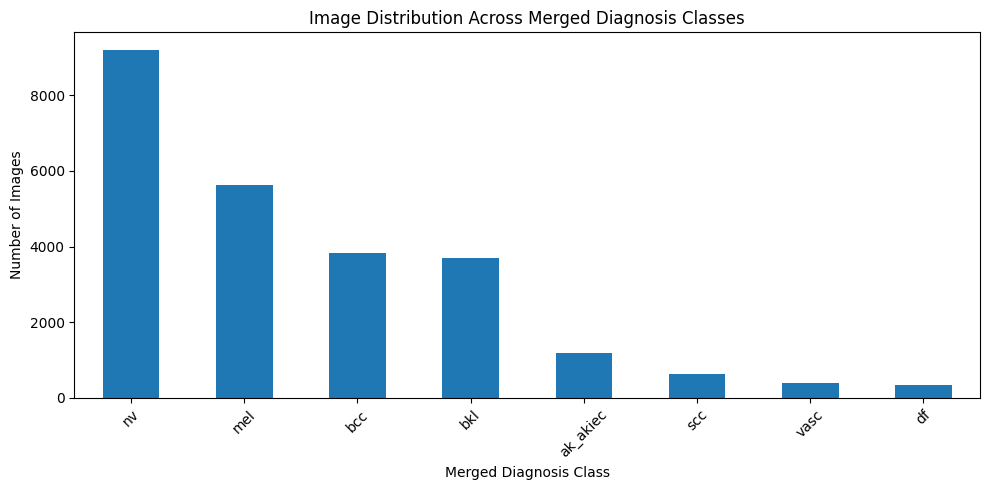

Largest class: nv
Largest class count: 9203
Smallest class: df
Smallest class count: 354
Imbalance ratio: 26.0


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Count images in each merged diagnosis class
print("1. IMAGE COUNT PER MERGED DIAGNOSIS CLASS")

class_counts = (
    df["diagnosis_merged"]
    .value_counts()
    .sort_values(ascending=False)
)

class_summary = pd.DataFrame({
    "image_count": class_counts,
    "percentage": (
        class_counts / len(df) * 100
    ).round(2)
})

display(class_summary)


# 2. Visualize merged class distribution
print("\n2. MERGED CLASS DISTRIBUTION")

plt.figure(figsize=(10, 5))

class_counts.plot(kind="bar")

plt.title("Image Distribution Across Merged Diagnosis Classes")
plt.xlabel("Merged Diagnosis Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Compare the largest and smallest classes
largest_class = class_counts.max()
smallest_class = class_counts.min()

imbalance_ratio = largest_class / smallest_class

print("Largest class:", class_counts.idxmax())
print("Largest class count:", largest_class)

print("Smallest class:", class_counts.idxmin())
print("Smallest class count:", smallest_class)

print("Imbalance ratio:", round(imbalance_ratio, 2))

In [9]:
# 1. Count each merged class in every split
print("1. MERGED CLASS COUNTS ACROSS SPLITS")

split_class_counts = pd.crosstab(
    df["split"],
    df["diagnosis_merged"]
)

display(split_class_counts)


# 2. Calculate merged class percentages within each split
print("\n2. MERGED CLASS PERCENTAGES WITHIN EACH SPLIT")

split_class_percentages = (
    pd.crosstab(
        df["split"],
        df["diagnosis_merged"],
        normalize="index"
    ) * 100
).round(2)

display(split_class_percentages)


# 3. Check total images in each split
print("\n3. TOTAL IMAGES PER SPLIT")

split_counts = df["split"].value_counts()

split_summary = pd.DataFrame({
    "image_count": split_counts,
    "percentage": (
        split_counts / len(df) * 100
    ).round(2)
})

display(split_summary)

1. MERGED CLASS COUNTS ACROSS SPLITS


diagnosis_merged,ak_akiec,bcc,bkl,df,mel,nv,scc,vasc
split,,,,,,,,
test,182,604,553,49,821,1384,95,65
train,830,2612,2607,238,4004,6444,448,281
val,174,614,549,67,800,1375,85,49



2. MERGED CLASS PERCENTAGES WITHIN EACH SPLIT


diagnosis_merged,ak_akiec,bcc,bkl,df,mel,nv,scc,vasc
split,,,,,,,,
test,4.85,16.09,14.73,1.31,21.88,36.88,2.53,1.73
train,4.75,14.96,14.93,1.36,22.93,36.90,2.57,1.61
val,4.69,16.54,14.79,1.80,21.55,37.03,2.29,1.32



3. TOTAL IMAGES PER SPLIT


,image_count,percentage
split,,
train,17464,70.05
test,3753,15.05
val,3713,14.89


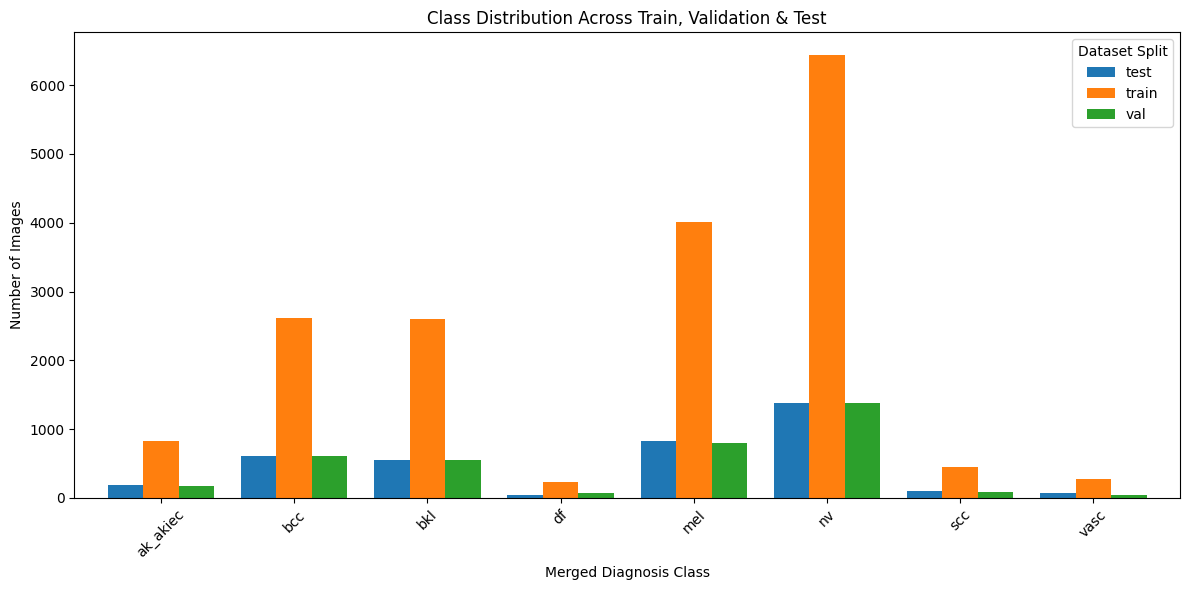

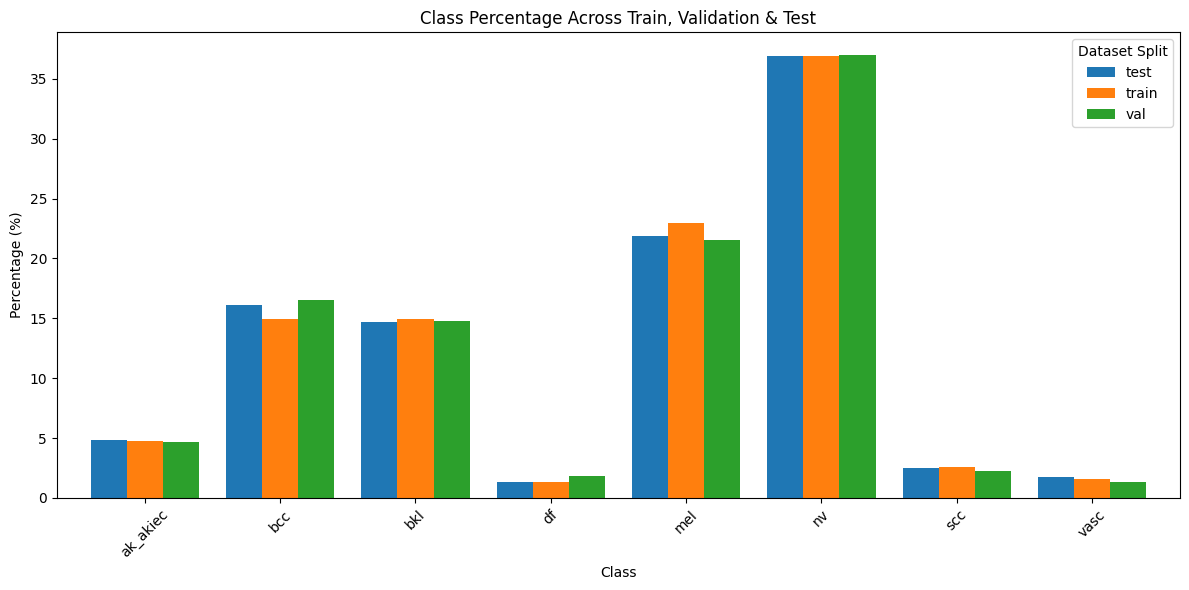

In [10]:
import matplotlib.pyplot as plt

# 4. Plot merged class counts across splits
split_class_counts.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Class Distribution Across Train, Validation & Test")
plt.xlabel("Merged Diagnosis Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()


# 5. Plot merged class percentages across splits
split_class_percentages.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Class Percentage Across Train, Validation & Test")
plt.xlabel( "Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

# Data Split & Data Leakage Analysis

In [11]:
# 1. Check image distribution across splits
print("=" * 60)
print("1. IMAGE COUNT PER SPLIT")
print("=" * 60)

display(
    df["split"].value_counts(dropna=False)
    .rename_axis("split")
    .reset_index(name="image_count")
)


# 2. Check whether the same group appears in multiple splits
print("\n" + "=" * 60)
print("2. GROUP OVERLAP ACROSS SPLITS")
print("=" * 60)

group_split_counts = (
    df.dropna(subset=["group_id", "split"])
    .groupby("group_id")["split"]
    .nunique()
)

overlapping_groups = group_split_counts[
    group_split_counts > 1
]

print("Groups appearing in multiple splits:", len(overlapping_groups))

if len(overlapping_groups) > 0:
    display(
        df[df["group_id"].isin(overlapping_groups.index)]
        .sort_values("group_id")[
            ["group_id", "source", "diagnosis_merged", "split"]
        ].head(20)
    )
else:
    print("No group overlap detected.")


# 3. Check duplicate image hashes across splits
print("\n" + "=" * 60)
print("3. IMAGE HASH OVERLAP ACROSS SPLITS")
print("=" * 60)

hash_split_counts = (
    df.dropna(subset=["sha256", "split"])
    .groupby("sha256")["split"]
    .nunique()
)

overlapping_hashes = hash_split_counts[
    hash_split_counts > 1
]

print("Image hashes appearing in multiple splits:", len(overlapping_hashes))

if len(overlapping_hashes) > 0:
    display(
        df[df["sha256"].isin(overlapping_hashes.index)]
        .sort_values("sha256")[
            ["sha256", "source", "diagnosis_merged", "split"]
        ].head(20)
    )
else:
    print("No cross-split hash overlap detected.")

1. IMAGE COUNT PER SPLIT


,split,image_count
0,train,17464
1,test,3753
2,val,3713



2. GROUP OVERLAP ACROSS SPLITS
Groups appearing in multiple splits: 0
No group overlap detected.

3. IMAGE HASH OVERLAP ACROSS SPLITS
Image hashes appearing in multiple splits: 0
No cross-split hash overlap detected.


# Image Distribution Across Data Splits

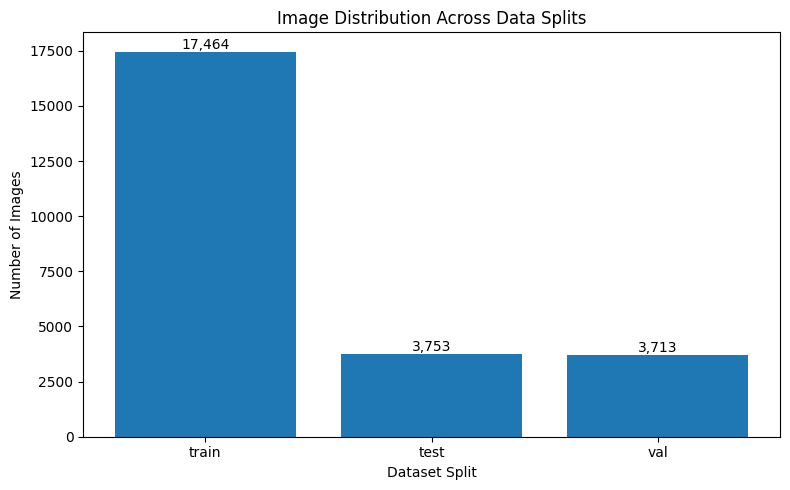

In [12]:

import matplotlib.pyplot as plt

# Count images in each split
split_counts = df["split"].value_counts()

# Plot image distribution
plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_counts.index,
    split_counts.values
)

plt.title("Image Distribution Across Data Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")

# Display count above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# Missing Value Flags Analysis

In [13]:

# 1. Check missing-value flags
print("=" * 60)
print("1. MISSING VALUE FLAGS SUMMARY")
print("=" * 60)

flag_columns = [
    "age_missing",
    "sex_missing",
    "site_missing"
]

for col in flag_columns:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).rename("count").to_frame())


# 2. Compare flags across dataset sources
print("\n" + "=" * 60)
print("2. MISSING VALUE FLAGS BY SOURCE")
print("=" * 60)

for col in flag_columns:
    print(f"\n{col} by source")
    display(pd.crosstab(df["source"], df[col], margins=True))


# 3. Compare flags with current metadata values
print("\n" + "=" * 60)
print("3. FLAGS VS CURRENT MISSING VALUES")
print("=" * 60)

flag_check = pd.DataFrame({
    "flagged_as_missing": [
        df["age_missing"].sum(),
        df["sex_missing"].sum(),
        df["site_missing"].sum()
    ],
    "currently_null": [
        df["age"].isna().sum(),
        df["sex"].isna().sum(),
        df["anatom_site_general_challenge"].isna().sum()
    ]
}, index=["age", "sex", "anatom_site_general_challenge"])

display(flag_check)


1. MISSING VALUE FLAGS SUMMARY

age_missing


,count
age_missing,
0,24685
1,245



sex_missing


,count
sex_missing,
0,24930



site_missing


...

sex_missing,0,All
source,,
HAM10000,10013,10013
ISIC2019,14917,14917
All,24930,24930



site_missing by source


site_missing,0,1,All
source,,,
HAM10000,10013,0,10013
ISIC2019,13960,957,14917
All,23973,957,24930



3. FLAGS VS CURRENT MISSING VALUES


,flagged_as_missing,currently_null
age,245,0
sex,0,0
anatom_site_general_challenge,957,0


# Age, Sex & Anatomical Site Distribution

1. AGE SUMMARY


count    24930.000000
mean        56.899118
std         17.269727
min          0.000000
25%         45.000000
50%         55.000000
75%         70.000000
max         85.000000
Name: age, dtype: float64

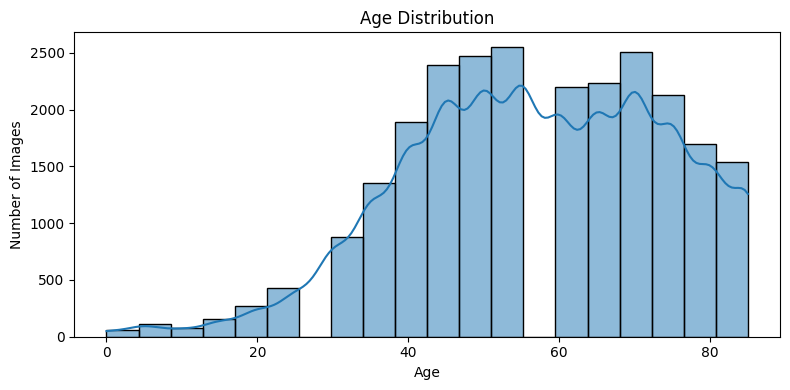


2. SEX DISTRIBUTION


,count
sex,
male,13612
female,11086
unknown,232


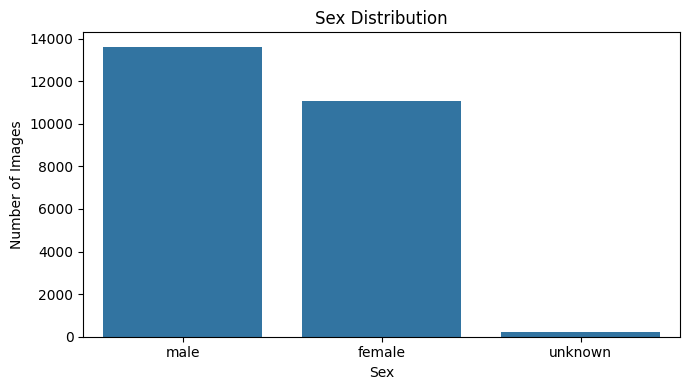


3. ANATOMICAL SITE DISTRIBUTION


,count
anatom_site_general_challenge,
lower extremity,4766
head/neck,3934
anterior torso,3916
upper extremity,2955
back,2191
trunk,1404
posterior torso,1268
unknown,1191
abdomen,1022


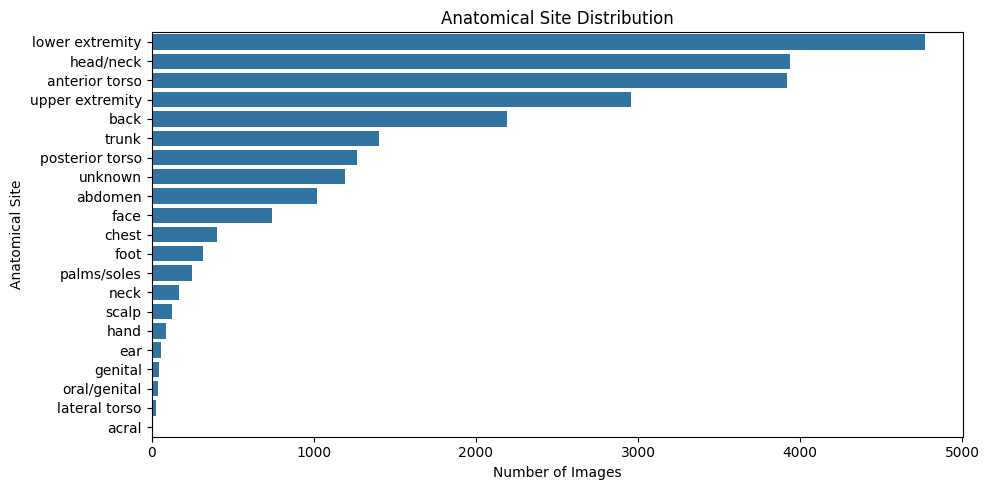

In [14]:
# Age, Sex & Anatomical Site Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Age distribution
print("1. AGE SUMMARY")
display(df["age"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


# 2. Sex distribution
print("\n2. SEX DISTRIBUTION")
display(
    df["sex"].value_counts(dropna=False)
      .rename("count")
      .to_frame()
)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="sex", order=df["sex"].value_counts().index)
plt.title("Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


# 3. Anatomical site distribution
print("\n3. ANATOMICAL SITE DISTRIBUTION")
display(
    df["anatom_site_general_challenge"]
      .value_counts(dropna=False)
      .rename("count")
      .to_frame()
)

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    y="anatom_site_general_challenge",
    order=df["anatom_site_general_challenge"].value_counts().index
)
plt.title("Anatomical Site Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Anatomical Site")
plt.tight_layout()
plt.show()

# Age Distribution by Diagnosis

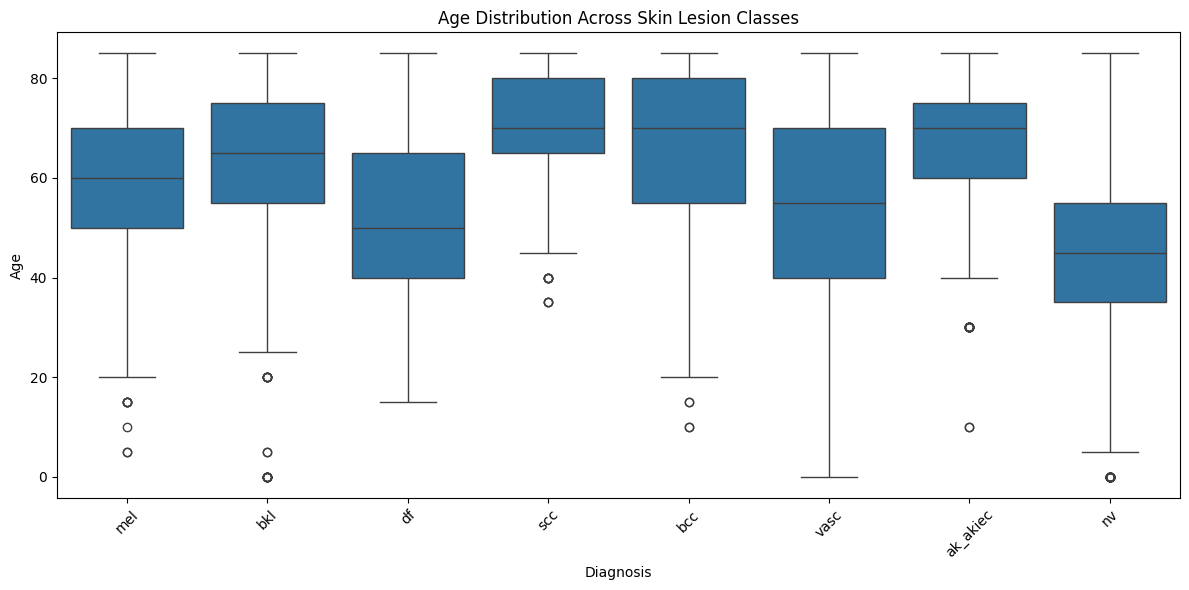

In [21]:
# Age Distribution by Diagnosis

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="diagnosis_merged",
    y="age"
)

plt.title("Age Distribution Across Skin Lesion Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Age")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

sex,female,male,unknown
diagnosis_merged,,,
ak_akiec,42.50,57.25,0.25
bcc,39.45,60.39,0.16
bkl,43.03,56.08,0.89
df,47.74,52.26,0.00
mel,42.70,55.86,1.44
nv,48.93,49.89,1.18
scc,32.32,67.68,0.00
vasc,50.13,49.87,0.00


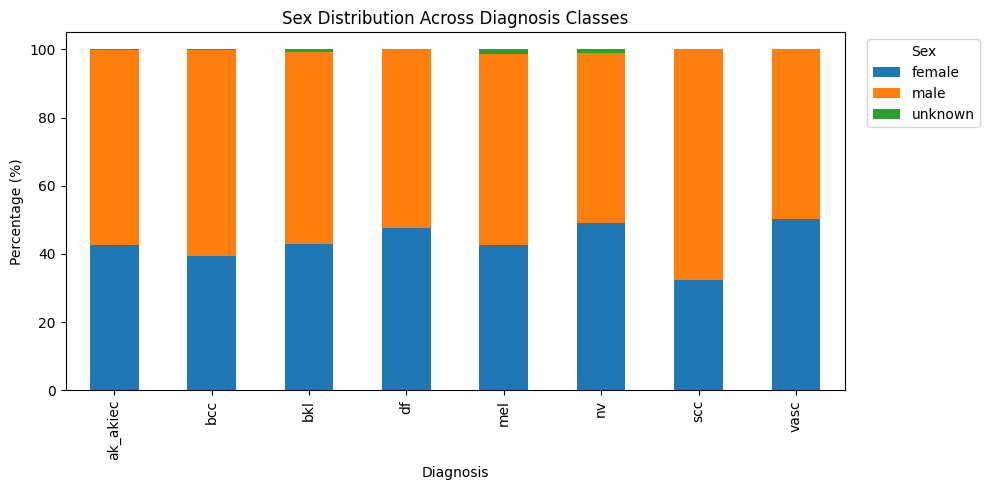

In [22]:
# Cell: Diagnosis Distribution by Sex

sex_diagnosis = pd.crosstab(
    df["diagnosis_merged"],
    df["sex"],
    normalize="index"
) * 100

display(sex_diagnosis.round(2))

sex_diagnosis.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Sex Distribution Across Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Percentage (%)")
plt.legend(title="Sex", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()